# Writing in the Air: extended evaluation and conclusions

This notebook goes beyond the mean ± std accuracy in `results/ablation_summary.csv` and checks the following:

1. **Are the differences real?** 95% bootstrap confidence intervals and paired McNemar tests.
2. **Which mitigation closes the domain gap best?** Share of the gap closed by each preprocessing variant.
3. **Who is hardest to read, and why?** Zero-shot accuracy per writer vs. stroke width.
4. **Why does augmentation hurt?** Stroke width of MNIST, augmented MNIST and our data.
5. **Which digits are confused, and how confident is the model when it is wrong?**
6. **Is the result robust to the one preprocessing hyperparameter?** Sensitivity to `TARGET_STROKE_RATIO`.
7. **What can fine-tuning and leave-one-writer-out tell us?** Ceiling check.

Every number shown here is produced by `metrics_analysis.py` and written to `results/metrics/` — the notebook only runs that script and reads its output, so all numbers can be quoted in the report.

**How to run.** From the repository root, after `train.py` has produced the checkpoints in `models/` (or after unpacking `models/` from the Colab `outputs.zip`): *Run all*. On Colab, the first cell clones the repository.

In [1]:
# On Colab: clone the repository and install the pinned dependencies.
# Locally (repo root as working directory) this cell does nothing.
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and not os.path.exists("metrics_analysis.py"):
    subprocess.run(["git", "clone", "-b", "metrics-analysis",
                    "https://github.com/KiriLLLL17/airwrite.git"], check=True)
    os.chdir("airwrite")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "scikit-learn==1.5.2", "opencv-contrib-python==4.10.0.84"], check=True)
print("working directory:", os.getcwd())

working directory: /tmp/awk


In [2]:
# Compute everything (inference only, about 1-3 minutes on a laptop CPU).
import subprocess, sys
res = subprocess.run([sys.executable, "metrics_analysis.py"], capture_output=True, text=True)
print(res.stdout[-1500:])
if res.returncode != 0:
    print(res.stderr[-3000:])
    raise RuntimeError("metrics_analysis.py failed")

      3 807    0.6328         296.3333    0.6006     0.6659
logreg centering      3 807    0.7456         205.3333    0.7170     0.7749
logreg      full      3 807    0.7997         161.6667    0.7736     0.8269
 model   variant  mnist_accuracy  ours_accuracy  gap_points  error_ratio_vs_mnist  gap_closed
   aug   minimal          0.9912         0.9434      4.7788                6.4305      0.0000
   aug thickness          0.9912         0.9496      4.1592                5.7264      0.1297
   aug centering          0.9912         0.9756      1.5570                2.7693      0.6742
   aug      full          0.9912         0.9719      1.9288                3.1918      0.5964
   cnn   minimal          0.9933         0.9653      2.8030                5.2045      0.0000
   cnn thickness          0.9933         0.9748      1.8530                3.7794      0.3389
   cnn centering          0.9933         0.9843      0.9029                2.3544      0.6779
   cnn      full          0.9933    

In [3]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

pd.set_option("display.precision", 4)
R = "results/metrics/"
F = "figures/metrics/"
ci    = pd.read_csv(R + "confidence_intervals.csv")
gap   = pd.read_csv(R + "gap_closed.csv")
mcn   = pd.read_csv(R + "mcnemar.csv")
wr    = pd.read_csv(R + "per_writer.csv")
pairs = pd.read_csv(R + "confusion_pairs.csv")
conf  = pd.read_csv(R + "confidence.csv")
sens  = pd.read_csv(R + "stroke_ratio_sensitivity.csv")
ceil  = pd.read_csv(R + "ceiling.csv")
used  = pd.read_csv(R + "checkpoints_used.csv")
domain = pd.read_csv("results/domain_stats.csv")

expected = {(m, s) for m in ("logreg", "cnn", "aug") for s in (42, 43, 44)}
missing = sorted(expected - set(zip(used.model, used.seed)))
display(used)
if missing:
    display(Markdown(
        f"**⚠ Preview run.** Missing checkpoints: `{missing}`. Numbers below cover only "
        "the models listed above. Add the full `models/` folder (from the Colab `outputs.zip`) "
        "and run the notebook again before quoting anything in the report."))
else:
    display(Markdown("All 9 checkpoints (3 models × 3 seeds) found — this is the full run."))

,model,seed,file
0,aug,42,cnn_aug_seed42.pt
1,aug,43,cnn_aug_seed43.pt
2,aug,44,cnn_aug_seed44.pt
3,cnn,42,cnn_mnist_seed42.pt
4,cnn,43,cnn_mnist_seed43.pt
5,cnn,44,cnn_mnist_seed44.pt
6,logreg,42,logreg_seed42.joblib
7,logreg,43,logreg_seed43.joblib
8,logreg,44,logreg_seed44.joblib


All 9 checkpoints (3 models × 3 seeds) found — this is the full run.

## 1. How precise are the accuracies?: 95% confidence intervals

The ± std in `ablation_summary.csv` only reflects **training randomness** (3 seeds). The test set is small: with 807 images, **one error = 0.12 points**. The interval below resamples the test images (bootstrap, 2000 resamples, images resampled jointly for all seeds), so it shows how much the accuracy could move with a different sample of digits.

In [4]:
t = ci.copy()
for c in ("accuracy", "ci95_low", "ci95_high"):
    t[c] = (100 * t[c]).round(2)
t.rename(columns={"accuracy": "accuracy %", "ci95_low": "CI low %", "ci95_high": "CI high %"})

,model,variant,seeds,n,accuracy %,errors_per_seed,CI low %,CI high %
0,aug,minimal,3,807,94.34,45.6667,92.89,95.79
1,aug,thickness,3,807,94.96,40.6667,93.51,96.32
2,aug,centering,3,807,97.56,19.6667,96.53,98.43
3,aug,full,3,807,97.19,22.6667,96.08,98.22
4,cnn,minimal,3,807,96.53,28.0000,95.46,97.52
5,cnn,thickness,3,807,97.48,20.3333,96.45,98.39
6,cnn,centering,3,807,98.43,12.6667,97.60,99.17
7,cnn,full,3,807,99.46,4.3333,98.97,99.83
8,logreg,minimal,3,807,55.47,359.3333,52.08,58.78
9,logreg,thickness,3,807,63.28,296.3333,60.06,66.59


## 2. Which mitigation closes the gap?: share of the domain gap closed

`gap closed = (acc_variant − acc_minimal) / (acc_MNIST − acc_minimal)`: 0 % = no better than minimal preprocessing, 100 % = back to the model's own MNIST test accuracy, > 100 % = better than on MNIST. This answers the research question directly and makes models with very different absolute accuracies comparable. `error_ratio_vs_mnist` shows how many times more errors the model makes on our digits than on MNIST.

,model,variant,mnist_accuracy,ours_accuracy,gap_points,error_ratio_vs_mnist,gap_closed %
0,aug,minimal,0.9912,0.9434,4.7788,6.4305,0.0
1,aug,thickness,0.9912,0.9496,4.1592,5.7264,13.0
2,aug,centering,0.9912,0.9756,1.5570,2.7693,67.4
3,aug,full,0.9912,0.9719,1.9288,3.1918,59.6
4,cnn,minimal,0.9933,0.9653,2.8030,5.2045,0.0
5,cnn,thickness,0.9933,0.9748,1.8530,3.7794,33.9
6,cnn,centering,0.9933,0.9843,0.9029,2.3544,67.8
7,cnn,full,0.9933,0.9946,-0.1297,0.8055,104.6
8,logreg,minimal,0.9235,0.5547,36.8737,5.8180,0.0
9,logreg,thickness,0.9235,0.6328,29.0670,4.7980,21.2


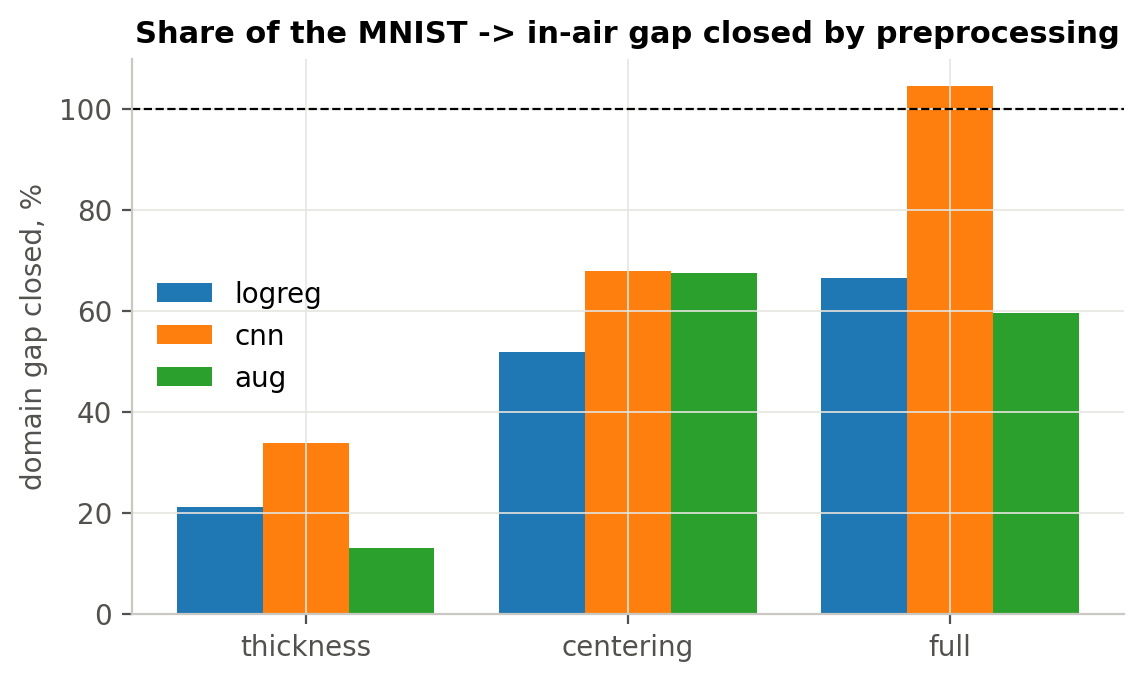

In [5]:
t = gap.copy()
t["gap_closed %"] = (100 * t.pop("gap_closed")).round(1)
display(t.round(4))
display(Image(F + "gap_closed.png", width=600))

## 3. Are the differences significant?: McNemar's test

All variants are evaluated on **the same 807 images**, so the right test is a **paired** one. McNemar's test only looks at the images where the two configurations disagree (`a_right_b_wrong` vs. `a_wrong_b_right`); if both were equally good, these would split 50/50. Several comparisons are made per seed, so p-values are Holm-corrected within each seed.

In [6]:
mcn

,config_a,config_b,seed,acc_a,acc_b,a_right_b_wrong,a_wrong_b_right,p_value,p_holm,significant_5pct
0,cnn/minimal,cnn/thickness,42,0.9703,0.9715,7,8,1.0000e+00,1.0000e+00,False
1,cnn/minimal,cnn/thickness,43,0.9628,0.9765,5,16,2.6604e-02,1.0641e-01,False
2,cnn/minimal,cnn/thickness,44,0.9628,0.9765,4,15,1.9211e-02,5.7632e-02,False
3,cnn/minimal,cnn/centering,42,0.9703,0.9876,5,19,6.6108e-03,2.6443e-02,True
4,cnn/minimal,cnn/centering,43,0.9628,0.9851,8,26,2.9351e-03,1.4675e-02,True
5,cnn/minimal,cnn/centering,44,0.9628,0.9802,6,20,9.3553e-03,3.7421e-02,True
6,cnn/minimal,cnn/full,42,0.9703,0.9963,0,21,9.5367e-07,5.7220e-06,True
7,cnn/minimal,cnn/full,43,0.9628,0.9938,2,27,1.6242e-06,1.1370e-05,True
8,cnn/minimal,cnn/full,44,0.9628,0.9938,0,25,5.9605e-08,4.1723e-07,True
9,cnn/thickness,cnn/centering,42,0.9715,0.9876,5,18,1.0622e-02,3.1866e-02,True


## 4. Who is hardest to read?: accuracy per writer and stroke width

Our strokes are **thinner** than MNIST (median width at 28×28, `results/domain_stats.csv`). With only four writers this is descriptive, not a statistical relationship.

,writer,stroke_width_median,fill_ratio_median
0,MNIST,2.436,0.130
1,kacper,1.553,0.073
2,kirill,1.394,0.070
3,mateusz,1.456,0.081
4,roman,0.899,0.052


model      aug            cnn         logreg        
variant   full minimal   full minimal   full minimal
writer                                              
kacper   99.50   98.83  99.83   98.33  87.33   65.00
kirill   95.50   91.33  99.00   97.17  71.33   52.33
mateusz  97.33   94.33  99.83   97.83  83.67   61.83
roman    96.46   92.91  99.19   92.91  77.62   43.16

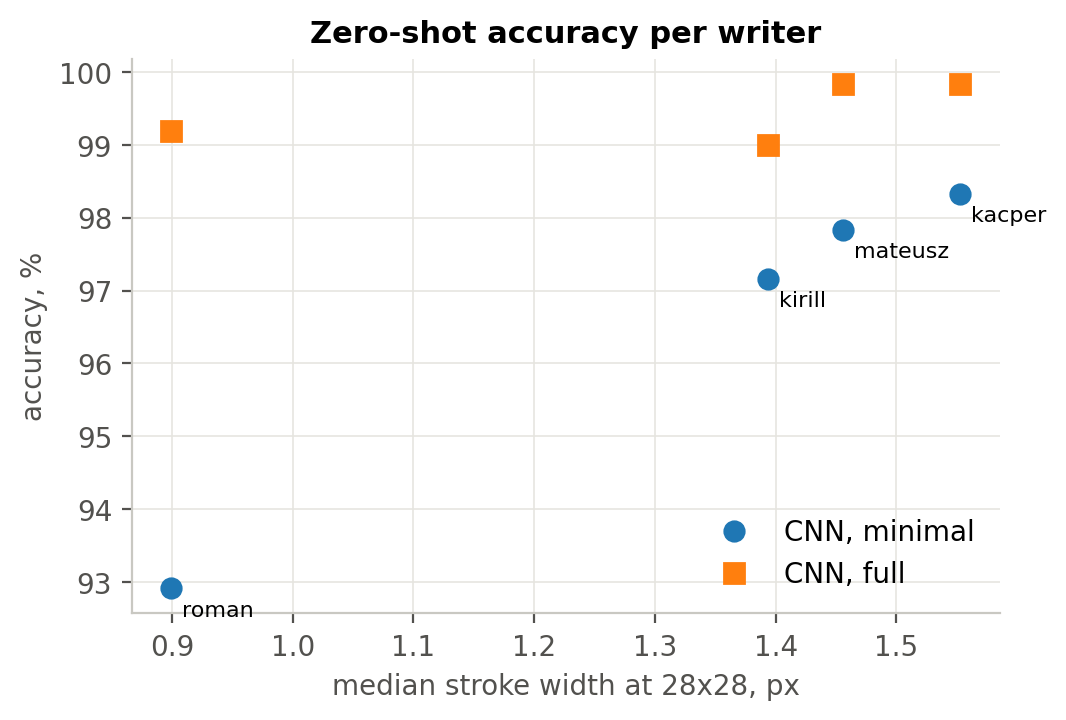

In [7]:
display(domain[["writer", "stroke_width_median", "fill_ratio_median"]].round(3))
t = wr[wr.variant.isin(["minimal", "full"])].copy()
t["accuracy_mean"] = (100 * t.accuracy_mean).round(2)
display(t.pivot_table(index="writer", columns=["model", "variant"], values="accuracy_mean"))
display(Image(F + "per_writer.png", width=520))

## 5. Why does augmentation hurt?

`train.py` augments MNIST with **dilation** (thicker strokes), rotation, shift and elastic warp. The original assumption was that in-air strokes are thick and uneven. The measurements say the opposite: our strokes are thinner than MNIST. If augmentation makes the training digits even thicker, it moves the training distribution **away** from our data.

,source,stroke_width_median
0,MNIST,2.436
1,MNIST augmented,3.237
2,kacper,1.553
3,kirill,1.394
4,mateusz,1.456
5,roman,0.899


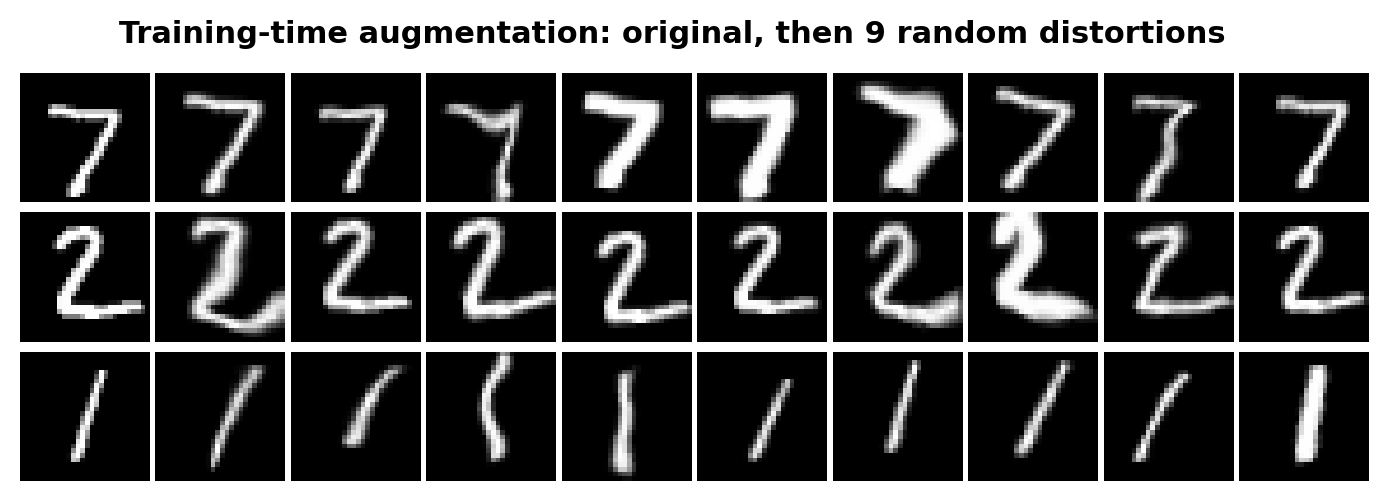

In [8]:
path = R + "augmentation_stroke_width.csv"
if os.path.exists(path):
    aw = pd.read_csv(path)
    ours = domain[domain.writer != "MNIST"][["writer", "stroke_width_median"]].rename(columns={"writer": "source"})
    display(pd.concat([aw[["source", "stroke_width_median"]], ours]).round(3).reset_index(drop=True))
else:
    print("MNIST was not available offline, so this check was skipped.")
display(Image("figures/augmentation_examples.png", width=600))

## 6. Which digits are confused?

Most frequent mistakes (true → predicted), averaged over seeds, with the share of the true class. Below: what these mistakes look like (CNN, minimal preprocessing, first seed).

In [9]:
show = pairs[pairs.model.eq("cnn") & pairs.variant.isin(["minimal", "full"])]
display(show.round(3))

,model,variant,label,pred,count,count_per_seed,share_of_true_class
43,cnn,full,1,7,5,1.667,0.021
44,cnn,full,6,3,3,1.000,0.012
45,cnn,full,4,1,2,0.667,0.008
46,cnn,full,6,5,1,0.333,0.004
47,cnn,full,9,0,1,0.333,0.004
48,cnn,full,9,3,1,0.333,0.004
49,cnn,minimal,6,5,19,6.333,0.075
50,cnn,minimal,7,1,18,6.000,0.074
51,cnn,minimal,1,7,11,3.667,0.046
52,cnn,minimal,9,3,11,3.667,0.046


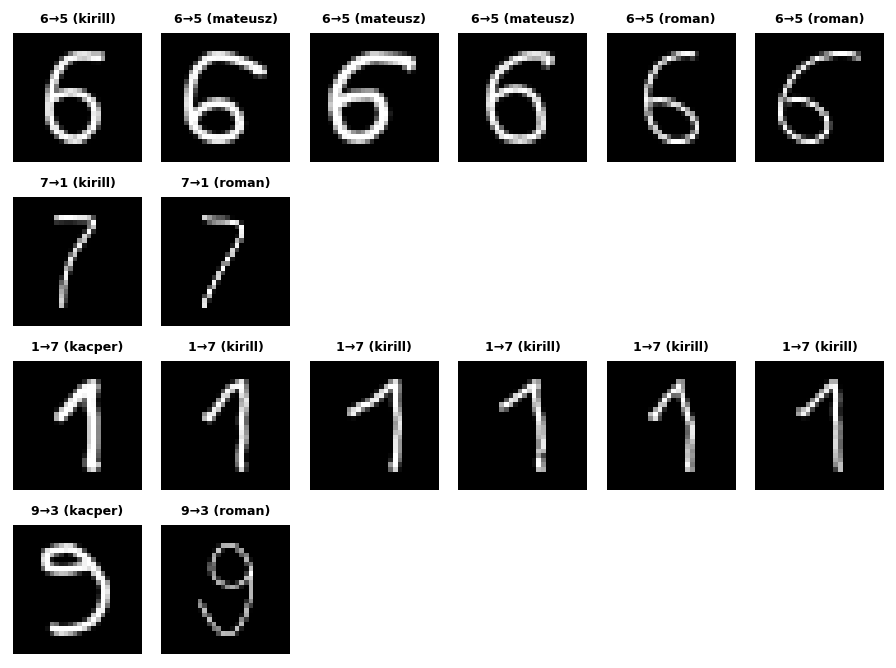

In [10]:
# Gallery of the most common confusions (display only, no new numbers).
from data_utils import load_target
from preprocessing import preprocess_many
from ablation import VARIANTS

raw, labels, writers = load_target(False)
x = preprocess_many(raw, VARIANTS["minimal"])
pred = pd.read_csv(R + "predictions.csv")
p = pred[(pred.model == "cnn") & (pred.variant == "minimal")]
p = p[p.seed == p.seed.min()]
top = show[show.variant == "minimal"].head(4)
fig, axes = plt.subplots(len(top), 6, figsize=(7, 1.3 * len(top)))
axes = np.atleast_2d(axes)
for row, (_, r) in zip(axes, top.iterrows()):
    idx = p[(p.label == r.label) & (p.pred == r.pred)].image.to_numpy()[:6]
    for ax in row:
        ax.axis("off")
    for ax, i in zip(row, idx):
        ax.imshow(x[i], cmap="gray")
        ax.set_title(f"{r.label}→{r.pred} ({writers[i]})", fontsize=7)
plt.tight_layout()
import io
buf = io.BytesIO(); fig.savefig(buf, format="png", dpi=130); plt.close(fig)
display(Image(buf.getvalue()))   # plotting.py selects the Agg backend, so show via PNG

## 7. How confident is the model when it is wrong?

The live demo shows the model's confidence. Under domain shift a model can be **confidently wrong**. `share_of_errors_confident` = share of mistakes made with softmax probability ≥ 0.9.

,model,variant,mean_conf_correct,mean_conf_wrong,errors_per_seed,share_of_errors_confident
0,aug,minimal,0.974,0.697,45.667,0.204
1,aug,thickness,0.988,0.767,40.667,0.254
2,aug,centering,0.975,0.663,19.667,0.203
3,aug,full,0.986,0.714,22.667,0.118
4,cnn,minimal,0.964,0.683,28.000,0.167
5,cnn,thickness,0.985,0.749,20.333,0.197
6,cnn,centering,0.979,0.604,12.667,0.026
7,cnn,full,0.992,0.703,4.333,0.154
8,logreg,minimal,0.786,0.607,359.333,0.093
9,logreg,thickness,0.889,0.710,296.333,0.254


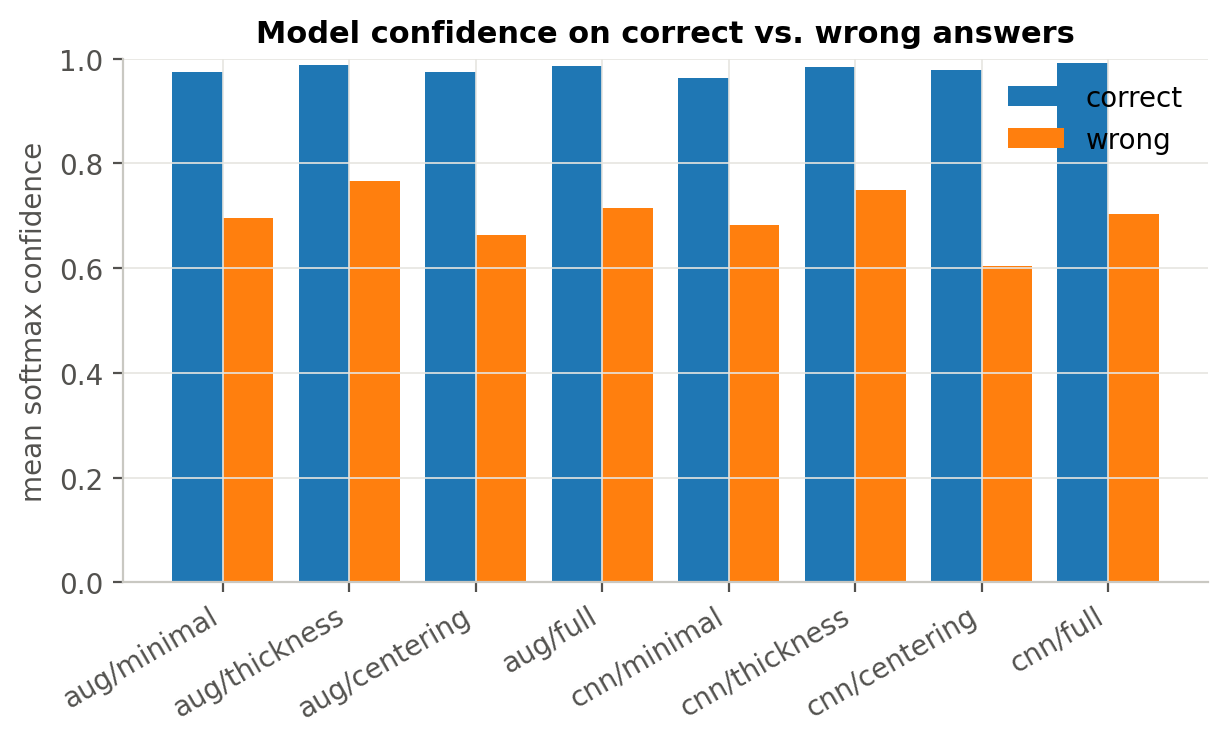

In [11]:
display(conf.round(3))
display(Image(F + "confidence.png", width=620))

## 8. Robustness to the stroke-width hyperparameter

`TARGET_STROKE_RATIO = 0.12` was fixed **before** our data was collected (it reproduces MNIST proportions). The curve below is a robustness check only. Choosing the best value from it would be tuning on the test set, so the main results keep 0.12.

,mean,std,count
stroke_ratio,,,
0.06,98.97,0.50,3
0.08,99.38,0.21,3
0.10,99.42,0.14,3
0.12,99.46,0.14,3
0.14,99.26,0.12,3
0.16,98.93,0.29,3
0.18,98.51,0.12,3


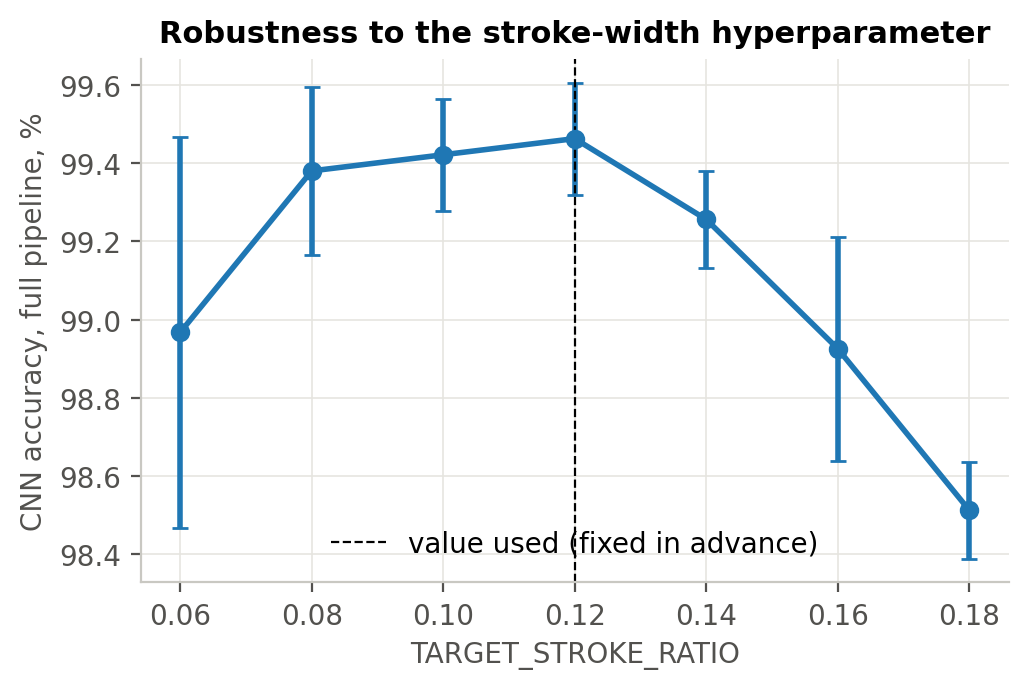

In [12]:
display(sens.groupby("stroke_ratio").accuracy.agg(["mean", "std", "count"]).mul([100, 100, 1]).round(2))
display(Image(F + "stroke_ratio_sensitivity.png", width=520))

## 9. Ceiling check: fine-tuning and leave-one-writer-out

When a model makes 0 errors on a test set, accuracy cannot rank interventions. `error_upper95` is a 95% upper bound on the true error rate (rule of three for 0 errors, Wilson otherwise).

In [13]:
ceil.groupby(["experiment", "group", "stage"]).agg(
    n=("n", "first"), errors_mean=("errors", "mean"), error_upper95=("error_upper95", "mean")).round(4)

n  errors_mean  error_upper95
experiment group   stage                                  
finetune   aug     after   243       0.3333         0.0159
                   before  243       7.6667         0.0615
           cnn     after   243       0.0000         0.0123
                   before  243       0.3333         0.0159
lowo       kacper  after   200       0.0000         0.0150
                   before  200       0.3333         0.0193
           kirill  after   200       0.0000         0.0150
                   before  200       2.0000         0.0357
           mateusz after   200       0.0000         0.0150
                   before  200       0.3333         0.0193
           roman   after   207       1.3333         0.0294
                   before  207       1.6667         0.0320

## 10. Conclusions

The summary below is generated from the CSV files, so it always matches the numbers above.

In [14]:
def acc(m, v):
    r = ci[(ci.model == m) & (ci.variant == v)]
    return None if r.empty else r.iloc[0]

def pct(x):
    return f"{100 * x:.2f}%"

lines = []
cmin, cfull = acc("cnn", "minimal"), acc("cnn", "full")
if cmin is not None:
    g = gap[(gap.model == "cnn") & (gap.variant == "minimal")].iloc[0]
    lines.append(f"**Domain gap.** The MNIST-trained CNN drops from {pct(g.mnist_accuracy)} on MNIST to "
                 f"{pct(cmin.accuracy)} on our digits (95% CI {pct(cmin.ci95_low)}–{pct(cmin.ci95_high)}), "
                 f"i.e. {g.error_ratio_vs_mnist:.1f}× more errors.")
if cfull is not None:
    g = gap[(gap.model == "cnn") & (gap.variant == "full")].iloc[0]
    lines.append(f"**Preprocessing closes the gap.** Full preprocessing gives {pct(cfull.accuracy)} "
                 f"(CI {pct(cfull.ci95_low)}–{pct(cfull.ci95_high)}), {100 * g.gap_closed:.0f}% of the gap closed.")
for v in ("thickness", "centering"):
    g = gap[(gap.model == "cnn") & (gap.variant == v)]
    if len(g):
        lines.append(f"CNN, {v} alone: {100 * g.gap_closed.iloc[0]:.0f}% of the gap closed.")
sig = mcn[mcn.config_a.str.startswith("cnn") & mcn.config_b.str.startswith("cnn")]
if len(sig):
    agg = sig.groupby(["config_a", "config_b"]).agg(seeds=("seed", "nunique"),
                                                     significant=("significant_5pct", "sum"))
    for (a, b), r in agg.iterrows():
        lines.append(f"McNemar {a} vs {b}: significant (Holm, 5%) in {r.significant} of {r.seeds} seed(s).")
lr_min, lr_full = acc("logreg", "minimal"), acc("logreg", "full")
if lr_min is not None:
    g = gap[(gap.model == "logreg") & (gap.variant == "minimal")].iloc[0]
    lines.append(f"**The linear baseline is not robust:** {pct(g.mnist_accuracy)} on MNIST → {pct(lr_min.accuracy)} "
                 f"on our digits; full preprocessing recovers it only to {pct(lr_full.accuracy)}.")
a_full = acc("aug", "full")
if a_full is not None and cfull is not None:
    lines.append(f"**Augmentation hurts:** augmented CNN {pct(a_full.accuracy)} vs. plain CNN {pct(cfull.accuracy)} "
                 "with full preprocessing.")
if os.path.exists(R + "augmentation_stroke_width.csv"):
    aw = pd.read_csv(R + "augmentation_stroke_width.csv").set_index("source").stroke_width_median
    ours = domain[domain.writer != "MNIST"].stroke_width_median
    lines.append(f"Stroke width (median, px): MNIST {aw['MNIST']:.2f}, augmented MNIST {aw['MNIST augmented']:.2f}, "
                 f"our writers {ours.min():.2f}–{ours.max():.2f}.")
w = wr[(wr.model == "cnn") & (wr.variant == "minimal")].sort_values("accuracy_mean")
if len(w):
    lines.append(f"Hardest writer at minimal preprocessing: {w.iloc[0].writer} ({pct(w.iloc[0].accuracy_mean)}, "
                 f"median stroke {w.iloc[0].stroke_width_median:.2f} px); easiest: {w.iloc[-1].writer} "
                 f"({pct(w.iloc[-1].accuracy_mean)}).")
s = sens.groupby("stroke_ratio").accuracy.mean()
if len(s):
    lines.append(f"Stroke-ratio sensitivity: CNN accuracy stays between {pct(s.min())} and {pct(s.max())} "
                 f"for TARGET_STROKE_RATIO {s.index.min()}–{s.index.max()}.")
c = conf[(conf.model == "cnn") & (conf.variant == "minimal")]
if len(c):
    c = c.iloc[0]
    lines.append(f"Confidence (CNN, minimal): {c.mean_conf_correct:.2f} on correct answers vs. "
                 f"{c.mean_conf_wrong:.2f} on mistakes; {100 * c.share_of_errors_confident:.0f}% of mistakes are made "
                 "with ≥ 0.9 confidence.")
display(Markdown("\n".join(f"- {l}" for l in lines)))

- **Domain gap.** The MNIST-trained CNN drops from 99.33% on MNIST to 96.53% on our digits (95% CI 95.46%–97.52%), i.e. 5.2× more errors.
- **Preprocessing closes the gap.** Full preprocessing gives 99.46% (CI 98.97%–99.83%), 105% of the gap closed.
- CNN, thickness alone: 34% of the gap closed.
- CNN, centering alone: 68% of the gap closed.
- McNemar cnn/centering vs cnn/full: significant (Holm, 5%) in 2 of 3 seed(s).
- McNemar cnn/minimal vs cnn/centering: significant (Holm, 5%) in 3 of 3 seed(s).
- McNemar cnn/minimal vs cnn/full: significant (Holm, 5%) in 3 of 3 seed(s).
- McNemar cnn/minimal vs cnn/thickness: significant (Holm, 5%) in 0 of 3 seed(s).
- McNemar cnn/thickness vs cnn/centering: significant (Holm, 5%) in 1 of 3 seed(s).
- **The linear baseline is not robust:** 92.35% on MNIST → 55.47% on our digits; full preprocessing recovers it only to 79.97%.
- **Augmentation hurts:** augmented CNN 97.19% vs. plain CNN 99.46% with full preprocessing.
- Stroke width (median, px): MNIST 2.44, augmented MNIST 3.24, our writers 0.90–1.55.
- Hardest writer at minimal preprocessing: roman (92.91%, median stroke 0.90 px); easiest: kacper (98.33%).
- Stroke-ratio sensitivity: CNN accuracy stays between 98.51% and 99.46% for TARGET_STROKE_RATIO 0.06–0.18.
- Confidence (CNN, minimal): 0.96 on correct answers vs. 0.68 on mistakes; 17% of mistakes are made with ≥ 0.9 confidence.

### Interpretation (for the Discussion section)

- **The domain gap is real but small for the CNN, and large for the linear model.** Pooling and shared convolution filters give the CNN some invariance to position and stroke shape; logistic regression weights individual pixels, so a digit that is shifted or drawn with a thinner line lands on different pixels.
- **Centring is the most effective single step.** MNIST digits are centred by centre of mass; our digits are only boxed, so their mass is off-centre. Stroke-thickness normalisation alone has a smaller and less consistent effect on the CNN — in some seeds it changes *which* images are wrong more than *how many* (see the McNemar counts) — but together with centring it closes the rest of the gap.
- **Augmentation was designed for the wrong shift.** It makes MNIST strokes thicker, while our whiteboard draws strokes that are thinner than MNIST. This is a hypothesis supported by the stroke-width measurements, not a proven cause; a test would be to retrain with erosion instead of dilation.
- **Typical confusions have a visual explanation (see the gallery):** 6 → 5 happens on 6s with a long, open upper arc and a small loop; 7 → 1 on 7s with a short top bar and a long straight stem; 1 → 7 comes almost entirely from one writing style, a 1 with a long flag; 9 → 3 on 9s with an open loop or a tail that curls back. These are writer habits, not tracking noise, and most of them disappear after full preprocessing (only 1 → 7 remains, about 2 per seed).
- **Fine-tuning and leave-one-writer-out are at the ceiling** (0 or almost 0 errors on ~200–250 images), so they cannot rank interventions with this amount of data. They only show that the error rate is below roughly 1–1.5%.
- **Limitations:** 4 writers, 807 images, one webcam, one session per writer, and the whiteboard renders clean strokes of constant width — which is probably why the gap is small. Per-writer results are descriptive only.